# MAKE_VIDEO · story text → cartoon video

**To make a new video**
1. Copy a file in `stories/` (for example `1_golden_mango.txt`), give it a new name, and write your own story in it  
   (format: see `SYNTAX.md` - it is just names, feelings and lines of dialogue).
2. Change `STORY` in the first cell below to your file.
3. Menu **Run → Run All Cells**. The video appears in `output/`.

Voices are made with free Microsoft neural voices (**internet needed once per new line**). Lines you did not change are reused, so editing a story is fast.

In [1]:
STORY = "stories/1_golden_mango.txt"     # <- change to your story file, e.g. "stories/2_smell_of_sweets.txt"

USE_DRAFT_VOICE_IF_OFFLINE = False        # True = if real voices fail, use a humming PLACEHOLDER (testing only!)

## 1 · Check this computer

In [2]:
from engine import check_setup
check_setup()

  OK   ffmpeg installed
  OK   Pillow 12.3.0
  !!   Bangla text shaping (raqm)   -> Bangla letters may look broken. Linux: sudo apt install libfribidi0 libraqm0 | macOS: brew install fribidi
  OK   numpy
  OK   fontTools
  OK   edge_tts
  OK   fonts/NotoSansBengali-Bold.ttf

Ready to go.


True

## 2 · Read the story

In [3]:
from engine.script import load_story, describe, ScriptError

try:
    story = load_story(STORY)
except ScriptError as e:
    print("PROBLEM IN YOUR STORY FILE\n")
    print(e)
    raise SystemExit("Fix the story file and run this cell again.")
describe(story)

Title: চতুর চাঁদু ও সোনালি আম
Characters: raja (রাজা), mantri (মন্ত্রী), chandu (চাঁদু)
Scenes: 3   Spoken lines: 17   Estimated length: about 102 seconds


In [4]:
# %pip install -U edge-tts

## 3 · Voices
Makes one voice file per line in `audio/`. Each character gets its own voice, speed, pitch and a *voice effect* (`fx`) that makes the voice deeper or higher, so characters sound different.  
Want to use your **own recording** instead? Save it as `audio/line_03.mp3` (the line number) - it is used automatically.

In [5]:
# from engine import audio

# try:
#     await audio.tts_all(story, "audio")
# except Exception as e:
#     print("\nReal voices could not be made:", e)
#     if USE_DRAFT_VOICE_IF_OFFLINE:
#         print("Making placeholder hum voices (NOT real speech) so you can test the animation.")
#         audio.make_all_draft_audio(story, "audio")
#     else:
#         print("Check your internet connection (and that edge-tts is installed: pip install edge-tts), then run this cell again.")

# status = audio.audio_status(story, "audio")
# print()
# for lid, who, state, text in status:
#     mark = {"real": "OK   ", "draft": "HUM  ", "missing": "MISSING"}[state]
#     print(f"{mark} {lid:16s} {who:8s} {text[:46]}")
# missing = [s for s in status if s[2] == "missing"]
# hum = [s for s in status if s[2] == "draft"]
# if hum:
#     print(f"\n!! {len(hum)} line(s) use the humming PLACEHOLDER. This is only a test - it is not the real voice.")
# if missing:
#     raise SystemExit(f"Stopped: {len(missing)} line(s) have no voice yet. Fix the problem above and run this cell again.")

In [6]:

from engine import audio
import traceback

print("Generating real voices...")

tts_error = None

try:
    await audio.tts_all(story, "audio")
except Exception as e:
    tts_error = e
    print("\nTTS ERROR:")
    traceback.print_exc()

status = audio.audio_status(story, "audio")

print("\n========== AUDIO STATUS ==========")

for lid, who, state, text in status:
    mark = {
        "real": "OK",
        "draft": "DRAFT",
        "missing": "MISSING"
    }.get(state, "UNKNOWN")

    print(f"{mark:8} | {lid:16} | {who:10} | {text[:60]}")

missing = [s for s in status if s[2] == "missing"]
draft = [s for s in status if s[2] == "draft"]
real = [s for s in status if s[2] == "real"]

print("\n========== SUMMARY ==========")
print("Real voices:", len(real))
print("Draft voices:", len(draft))
print("Missing voices:", len(missing))

if missing:
    print("\nMissing dialogue IDs:")
    for item in missing:
        print(item[0], "-", item[1], "-", item[3][:80])

    print("\nDo not render the final video yet.")
else:
    print("\nAll dialogue lines have audio!")


Generating real voices...
  have   line_01_b4695c
  have   line_02_f63d3a
  have   line_03_ead81a
  have   line_04_806d01
  have   line_05_11acca
  have   line_06_bfcbf3
  have   line_07_8c0e0a
  have   line_08_92a1f3
  have   line_09_f034cc
  have   line_10_7346ac
  have   line_11_aae012
  have   line_12_cfc75c
  have   line_13_0c5517
  have   line_14_84febe
  have   line_15_5d8256
  have   line_16_1a705e
  have   line_17_57b4e6

Done. 0 new voice file(s).

========== AUDIO STATUS ==========
OK       | line_01_b4695c   | raja       | আমার সোনালি আম কোথায়? আজ সকালেও তো গাছে ঝুলছিল!
OK       | line_02_f63d3a   | mantri     | মহারাজ, আমি নিজের চোখে দেখেছি, ভোরবেলা বাগানে ঘুরঘুর করছিল আ
OK       | line_03_ead81a   | chandu     | আমি? মহারাজ, আমি তো কেবল ফুলের গন্ধ শুঁকতে এসেছিলাম!
OK       | line_04_806d01   | raja       | চুপ! আজ সন্ধ্যার মধ্যে আসল চোর ধরতে না পারলে, তোমার শাস্তি হ
OK       | line_05_11acca   | chandu     | ঠিক আছে মহারাজ। সন্ধ্যায় সভায় সবার সামনে চোর ধরিয়ে দেব।
OK  

Listen to the first lines:

In [7]:
from IPython.display import Audio, display
for lid, who, state, text in status[:3]:
    p = audio.find_audio("audio", lid)
    if p:
        print(who, "-", text[:50])
        display(Audio(str(p)))

raja - আমার সোনালি আম কোথায়? আজ সকালেও তো গাছে ঝুলছিল!


mantri - মহারাজ, আমি নিজের চোখে দেখেছি, ভোরবেলা বাগানে ঘুরঘ


chandu - আমি? মহারাজ, আমি তো কেবল ফুলের গন্ধ শুঁকতে এসেছিলা


## 4 · Preview some frames (quick, no video yet)

Video length: 119 seconds (2.0 min)


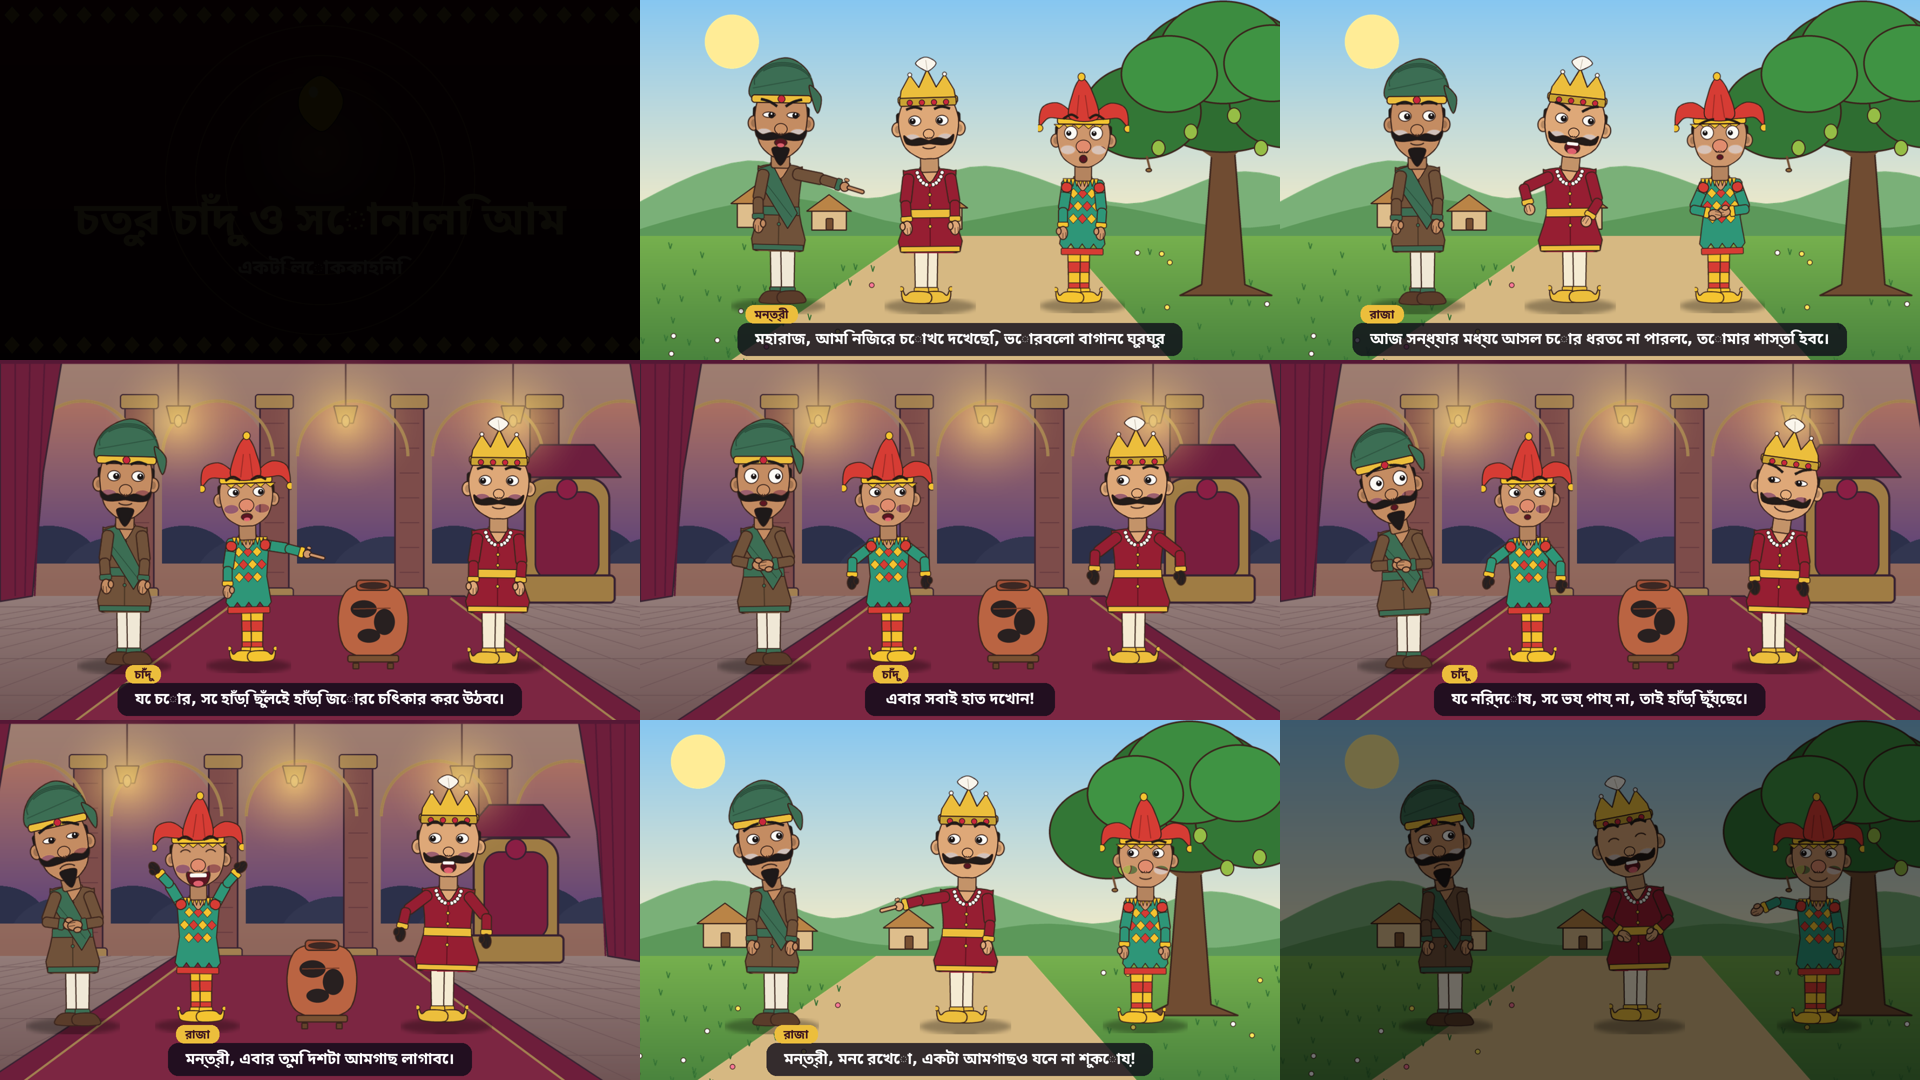

In [8]:
from engine.render import Studio

studio = Studio(".", STORY, draft=USE_DRAFT_VOICE_IF_OFFLINE)
total = studio.tl.total
print(f"Video length: {total:.0f} seconds ({total / 60:.1f} min)")
times = [total * f for f in (0.03, 0.12, 0.25, 0.38, 0.5, 0.62, 0.75, 0.88, 0.97)]
studio.contact_sheet(times, cols=3, scale=0.5)

## 5 · Render the video
About 1–2 minutes for a 2 minute video.

In [9]:
from pathlib import Path
from IPython.display import Video

out = f"output/{Path(STORY).stem}.mp4"
studio.render(out)
Video(out, width=800)

     0.0s / 119.3s  (  0%)  elapsed    0s
    10.0s / 119.3s  (  8%)  elapsed    5s
    20.0s / 119.3s  ( 17%)  elapsed   10s
    30.0s / 119.3s  ( 25%)  elapsed   17s
    40.0s / 119.3s  ( 34%)  elapsed   23s
    50.0s / 119.3s  ( 42%)  elapsed   29s
    60.0s / 119.3s  ( 50%)  elapsed   38s
    70.0s / 119.3s  ( 59%)  elapsed   45s
    80.0s / 119.3s  ( 67%)  elapsed   50s
    90.0s / 119.3s  ( 75%)  elapsed   55s
   100.0s / 119.3s  ( 84%)  elapsed   60s
   110.0s / 119.3s  ( 92%)  elapsed   66s
Saved output/1_golden_mango.mp4  (119.3 s, 71 s to render)


## Housekeeping (optional)
Shows voice files that the current story no longer uses. Set `delete=True` to remove them.

In [10]:
audio.clean_unused_audio(story, "audio", delete=False)

unused  .gitkeep


[PosixPath('audio/.gitkeep')]

In [11]:
from PIL import ImageFont, features

print("Pillow RAQM support:", features.check("raqm"))
print("HarfBuzz support:", features.check("harfbuzz"))
print("FriBidi support:", features.check("fribidi"))

Pillow RAQM support: False
HarfBuzz support: False
FriBidi support: False
